In [1]:
%pip install numpy pandas matplotlib seaborn scipy scikit-learn statsmodels requests gprofiler-official networkx

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import networkx as nx

from gprofiler import GProfiler

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from IPython.display import display
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:

candidate_genes = pd.DataFrame({
    "Gene_ID": [
        "AT5G05410",
        "AT5G52310",
        "AT5G52300",
        "AT3G14440",
        "AT1G45249",
        "AT4G34000",
        "AT2G39800",
        "AT5G66400",
        "AT2G42540",
        "AT5G25610",
        "AT5G51070",
        "AT4G33950",
        "AT4G26080",
        "AT2G36270",
        "AT5G05440"
    ],

    "Gene_Name": [
        "DREB2A",
        "RD29A",
        "RD29B",
        "NCED3",
        "AREB1",
        "ABF3",
        "P5CS1",
        "RAB18",
        "COR15A",
        "RD22",
        "ERD1",
        "OST1",
        "ABI1",
        "ABI5",
        "PYL5"
    ],

    "Functional_Category": [
        "Transcription factor",
        "Drought response",
        "Drought response",
        "ABA biosynthesis",
        "ABA signaling",
        "ABA signaling",
        "Osmotic stress",
        "Stress response",
        "Stress protection",
        "Drought response",
        "Stress response",
        "ABA signaling",
        "ABA signaling",
        "Transcription factor",
        "ABA receptor"
    ]
})

display(candidate_genes)

print("Total candidate genes:", len(candidate_genes))


,Gene_ID,Gene_Name,Functional_Category
0,AT5G05410,DREB2A,Transcription factor
1,AT5G52310,RD29A,Drought response
2,AT5G52300,RD29B,Drought response
3,AT3G14440,NCED3,ABA biosynthesis
4,AT1G45249,AREB1,ABA signaling
5,AT4G34000,ABF3,ABA signaling
6,AT2G39800,P5CS1,Osmotic stress
7,AT5G66400,RAB18,Stress response
8,AT2G42540,COR15A,Stress protection
9,AT5G25610,RD22,Drought response


Total candidate genes: 15


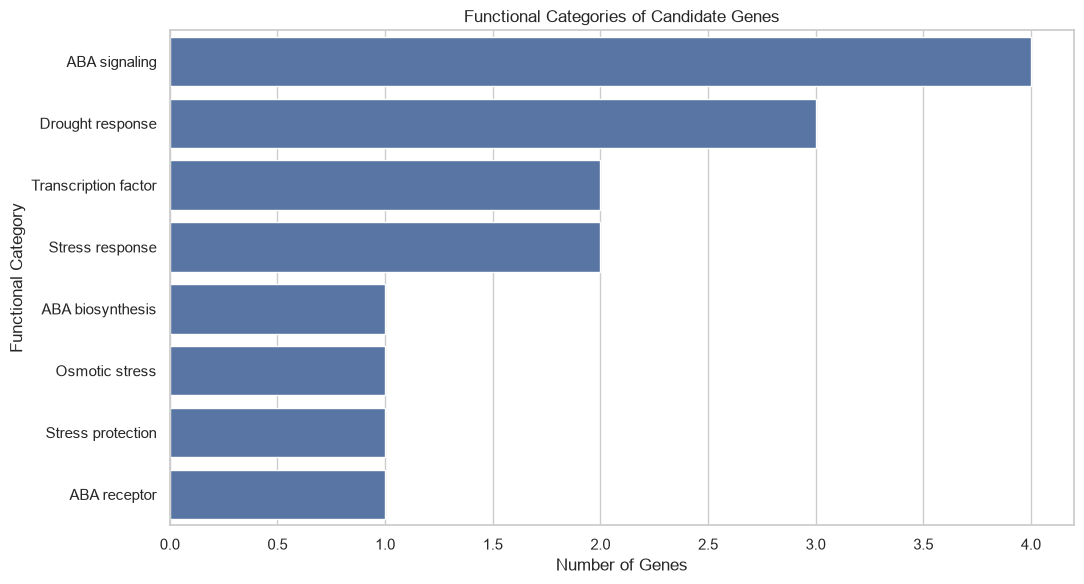

In [4]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=candidate_genes,
    y="Functional_Category",
    order=candidate_genes["Functional_Category"].value_counts().index
)

plt.title("Functional Categories of Candidate Genes")
plt.xlabel("Number of Genes")
plt.ylabel("Functional Category")

plt.tight_layout()
plt.show()

In [5]:

gp = GProfiler(return_dataframe=True)

print("g:Profiler connection initialized!")


g:Profiler connection initialized!


In [6]:

gene_list = candidate_genes["Gene_ID"].tolist()

annotation_results = gp.profile(
    organism="athaliana",
    query=gene_list,
    sources=["GO:BP", "GO:MF", "GO:CC"]
)

if annotation_results is not None and not annotation_results.empty:
    print("Functional annotation completed!")
    display(annotation_results.head(15))
else:
    print("No annotation results returned.")


Functional annotation completed!


,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
0,GO:BP,GO:0009414,response to water deprivation,6.296603e-14,True,"""Any process that results in a change in state...",424,15,11,21844,0.733333,0.025943,query_1,"[GO:0006950, GO:0009415]"
1,GO:BP,GO:0009415,response to water,8.572724e-14,True,"""Any process that results in a change in state...",436,15,11,21844,0.733333,0.025229,query_1,"[GO:0001101, GO:0009628, GO:1901700]"
2,GO:BP,GO:0001101,response to acid chemical,1.705076e-13,True,"""Any process that results in a change in state...",464,15,11,21844,0.733333,0.023707,query_1,[GO:0042221]
3,GO:BP,GO:0009651,response to salt stress,1.191981e-11,True,"""Any process that results in a change in state...",446,15,10,21844,0.666667,0.022422,query_1,[GO:0006970]
4,GO:BP,GO:0006970,response to osmotic stress,7.617218e-11,True,"""Any process that results in a change in state...",537,15,10,21844,0.666667,0.018622,query_1,"[GO:0006950, GO:0009628]"
5,GO:BP,GO:1901700,response to oxygen-containing compound,9.353935e-11,True,"""Any process that results in a change in state...",1660,15,13,21844,0.866667,0.007831,query_1,[GO:0042221]
6,GO:BP,GO:0009737,response to abscisic acid,2.456448e-10,True,"""Any process that results in a change in state...",604,15,10,21844,0.666667,0.016556,query_1,"[GO:0009725, GO:0033993, GO:0097305]"
7,GO:BP,GO:0097305,response to alcohol,2.845701e-10,True,"""Any process that results in a change in state...",613,15,10,21844,0.666667,0.016313,query_1,[GO:1901700]
8,GO:BP,GO:0009628,response to abiotic stimulus,2.327003e-09,True,"""Any process that results in a change in state...",2131,15,13,21844,0.866667,0.006100,query_1,[GO:0050896]
9,GO:BP,GO:0033993,response to lipid,4.453849e-08,True,"""Any process that results in a change in state...",1022,15,10,21844,0.666667,0.009785,query_1,[GO:0042221]


In [7]:

if not annotation_results.empty:

    annotation_table = annotation_results[
        [
            "source",
            "native",
            "name",
            "p_value",
            "intersection_size"
        ]
    ].copy()

    annotation_table = annotation_table.sort_values(
        "p_value"
    )

    display(annotation_table.head(20))


,source,native,name,p_value,intersection_size
0,GO:BP,GO:0009414,response to water deprivation,6.296603e-14,11
1,GO:BP,GO:0009415,response to water,8.572724e-14,11
2,GO:BP,GO:0001101,response to acid chemical,1.705076e-13,11
3,GO:BP,GO:0009651,response to salt stress,1.191981e-11,10
4,GO:BP,GO:0006970,response to osmotic stress,7.617218e-11,10
5,GO:BP,GO:1901700,response to oxygen-containing compound,9.353935e-11,13
6,GO:BP,GO:0009737,response to abscisic acid,2.456448e-10,10
7,GO:BP,GO:0097305,response to alcohol,2.845701e-10,10
8,GO:BP,GO:0009628,response to abiotic stimulus,2.327003e-09,13
9,GO:BP,GO:0033993,response to lipid,4.453849e-08,10


In [8]:

go_bp = annotation_results[
    annotation_results["source"] == "GO:BP"
].copy()

go_bp = go_bp.sort_values("p_value")

display(
    go_bp[
        [
            "native",
            "name",
            "p_value",
            "intersection_size"
        ]
    ].head(15)
)


,native,name,p_value,intersection_size
0,GO:0009414,response to water deprivation,6.296603e-14,11
1,GO:0009415,response to water,8.572724e-14,11
2,GO:0001101,response to acid chemical,1.705076e-13,11
3,GO:0009651,response to salt stress,1.191981e-11,10
4,GO:0006970,response to osmotic stress,7.617218e-11,10
5,GO:1901700,response to oxygen-containing compound,9.353935e-11,13
6,GO:0009737,response to abscisic acid,2.456448e-10,10
7,GO:0097305,response to alcohol,2.845701e-10,10
8,GO:0009628,response to abiotic stimulus,2.327003e-09,13
9,GO:0033993,response to lipid,4.453849e-08,10


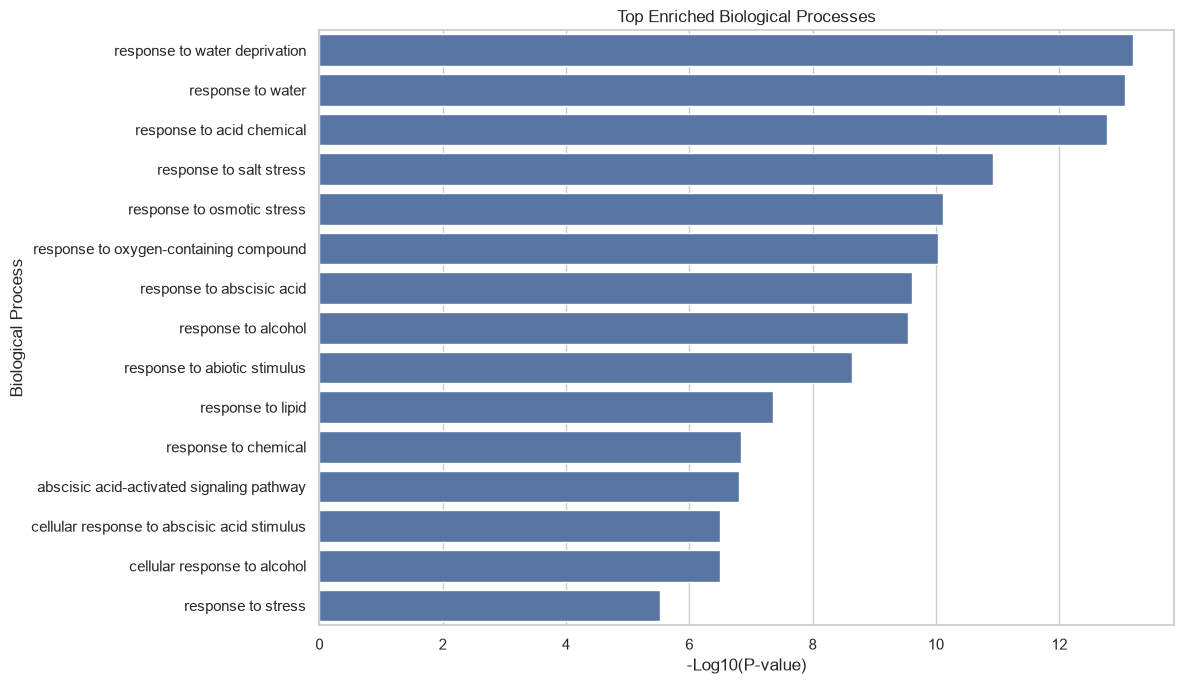

In [9]:

top_go = go_bp.head(15).copy()

if not top_go.empty:

    top_go["-log10(p-value)"] = -np.log10(
        top_go["p_value"].clip(lower=1e-300)
    )

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=top_go,
        x="-log10(p-value)",
        y="name"
    )

    plt.title("Top Enriched Biological Processes")
    plt.xlabel("-Log10(P-value)")
    plt.ylabel("Biological Process")

    plt.tight_layout()
    plt.show()
else:
    print("No Biological Process terms found.")


In [10]:

significant_go = annotation_results[
    annotation_results["p_value"] < 0.05
].copy()

print("Significant GO and functional terms:")
print(len(significant_go))

display(
    significant_go[
        ["source", "name", "p_value"]
    ].head(20)
)


Significant GO and functional terms:
34


,source,name,p_value
0,GO:BP,response to water deprivation,6.296603e-14
1,GO:BP,response to water,8.572724e-14
2,GO:BP,response to acid chemical,1.705076e-13
3,GO:BP,response to salt stress,1.191981e-11
4,GO:BP,response to osmotic stress,7.617218e-11
5,GO:BP,response to oxygen-containing compound,9.353935e-11
6,GO:BP,response to abscisic acid,2.456448e-10
7,GO:BP,response to alcohol,2.845701e-10
8,GO:BP,response to abiotic stimulus,2.327003e-09
9,GO:BP,response to lipid,4.453849e-08


In [11]:

string_genes = candidate_genes["Gene_ID"].tolist()

string_url = "https://string-db.org/api/tsv/network"

params = {
    "identifiers": "%0d".join(string_genes),
    "species": 3702,
    "required_score": 400
}

print("Prepared genes for STRING analysis.")
print("Number of genes:", len(string_genes))


Prepared genes for STRING analysis.
Number of genes: 15


In [20]:

import requests
import pandas as pd
from io import StringIO

string_url = "https://string-db.org/api/tsv/network"

params = {
    "identifiers": "\r".join(candidate_genes["Gene_ID"].tolist()),
    "species": 3702,
    "required_score": 150,
    "limit": 10
}

response = requests.get(
    string_url,
    params=params,
    timeout=120
)

print("Status code:", response.status_code)
response.raise_for_status()

if response.text.strip():

    ppi_data = pd.read_csv(
        StringIO(response.text),
        sep="\t"
    )

    print("Retrieved interactions:", len(ppi_data))
    display(ppi_data.head(10))

else:
    print("STRING returned an empty response.")


Status code: 200
Retrieved interactions: 261


,stringId_A,stringId_B,preferredName_A,preferredName_B,ncbiTaxonId,score,nscore,fscore,pscore,ascore,escore,dscore,tscore
0,3702.O49686,3702.P42759,PYR1,ERD10,3702,0.162,0.0,0,0.0,0.000,0.0,0.0,0.162
1,3702.O49686,3702.P30185,PYR1,RAB18,3702,0.179,0.0,0,0.0,0.000,0.0,0.0,0.179
2,3702.O49686,3702.P54887,PYR1,P5CSA,3702,0.185,0.0,0,0.0,0.000,0.0,0.0,0.185
3,3702.O49686,3702.Q9C6H5,PYR1,WRKY63,3702,0.187,0.0,0,0.0,0.000,0.0,0.0,0.187
4,3702.O49686,3702.Q8S8E3,PYR1,PYL6,3702,0.265,0.0,0,0.0,0.210,0.0,0.0,0.108
5,3702.O49686,3702.P31168,PYR1,COR47,3702,0.274,0.0,0,0.0,0.000,0.0,0.0,0.274
6,3702.O49686,3702.Q9FLB1,PYR1,PYL5,3702,0.310,0.0,0,0.0,0.258,0.0,0.0,0.109
7,3702.O49686,3702.Q42512,PYR1,COR15A,3702,0.350,0.0,0,0.0,0.000,0.0,0.0,0.350
8,3702.O49686,3702.Q08298,PYR1,RD22,3702,0.444,0.0,0,0.0,0.000,0.0,0.0,0.444
9,3702.O49686,3702.Q9M0L0,PYR1,DREB1A,3702,0.448,0.0,0,0.0,0.000,0.0,0.0,0.448


In [21]:

print("HTTP Status:", response.status_code)
print("Response length:", len(response.text))
print("\nSTRING response preview:")
print(response.text[:2000])

print("\nDataFrame shape:", ppi_data.shape)
print("Columns:", ppi_data.columns.tolist())


HTTP Status: 200
Response length: 17659

STRING response preview:
stringId_A	stringId_B	preferredName_A	preferredName_B	ncbiTaxonId	score	nscore	fscore	pscore	ascore	escore	dscore	tscore
3702.O49686	3702.P42759	PYR1	ERD10	3702	0.162	0	0	0	0	0	0	0.162
3702.O49686	3702.P30185	PYR1	RAB18	3702	0.179	0	0	0	0	0	0	0.179
3702.O49686	3702.P54887	PYR1	P5CSA	3702	0.185	0	0	0	0	0	0	0.185
3702.O49686	3702.Q9C6H5	PYR1	WRKY63	3702	0.187	0	0	0	0	0	0	0.187
3702.O49686	3702.Q8S8E3	PYR1	PYL6	3702	0.265	0	0	0	0.21	0	0	0.108
3702.O49686	3702.P31168	PYR1	COR47	3702	0.274	0	0	0	0	0	0	0.274
3702.O49686	3702.Q9FLB1	PYR1	PYL5	3702	0.31	0	0	0	0.258	0	0	0.109
3702.O49686	3702.Q42512	PYR1	COR15A	3702	0.35	0	0	0	0	0	0	0.35
3702.O49686	3702.Q08298	PYR1	RD22	3702	0.444	0	0	0	0	0	0	0.444
3702.O49686	3702.Q9M0L0	PYR1	DREB1A	3702	0.448	0	0	0	0	0	0	0.448
3702.O49686	3702.O82132	PYR1	DREB2A	3702	0.603	0	0	0	0	0	0	0.603
3702.O49686	3702.Q06738	PYR1	RD29A	3702	0.74	0	0	0	0	0	0	0.74
3702.O49686	3702.Q04980	PYR1	LTI65	3702	0.

Number of input genes: 15
STRING API status: 200
Retrieved interactions: 99

NETWORK STATISTICS
----------------------
Number of proteins: 15
Number of interactions: 99

TOP HUB PROTEINS


,Protein,Degree_Centrality,Betweenness_Centrality,Interaction_Count
0,DREB2A,1.000000,0.006516,14
5,ABI5,1.000000,0.006516,14
7,ABI1,1.000000,0.006516,14
8,NCED3,1.000000,0.006516,14
9,COR15A,1.000000,0.006516,14
11,ABF3,1.000000,0.006516,14
12,ABF2,1.000000,0.006516,14
13,LTI65,1.000000,0.006516,14
14,RD29A,1.000000,0.006516,14
3,SRK2E,0.928571,0.003297,13


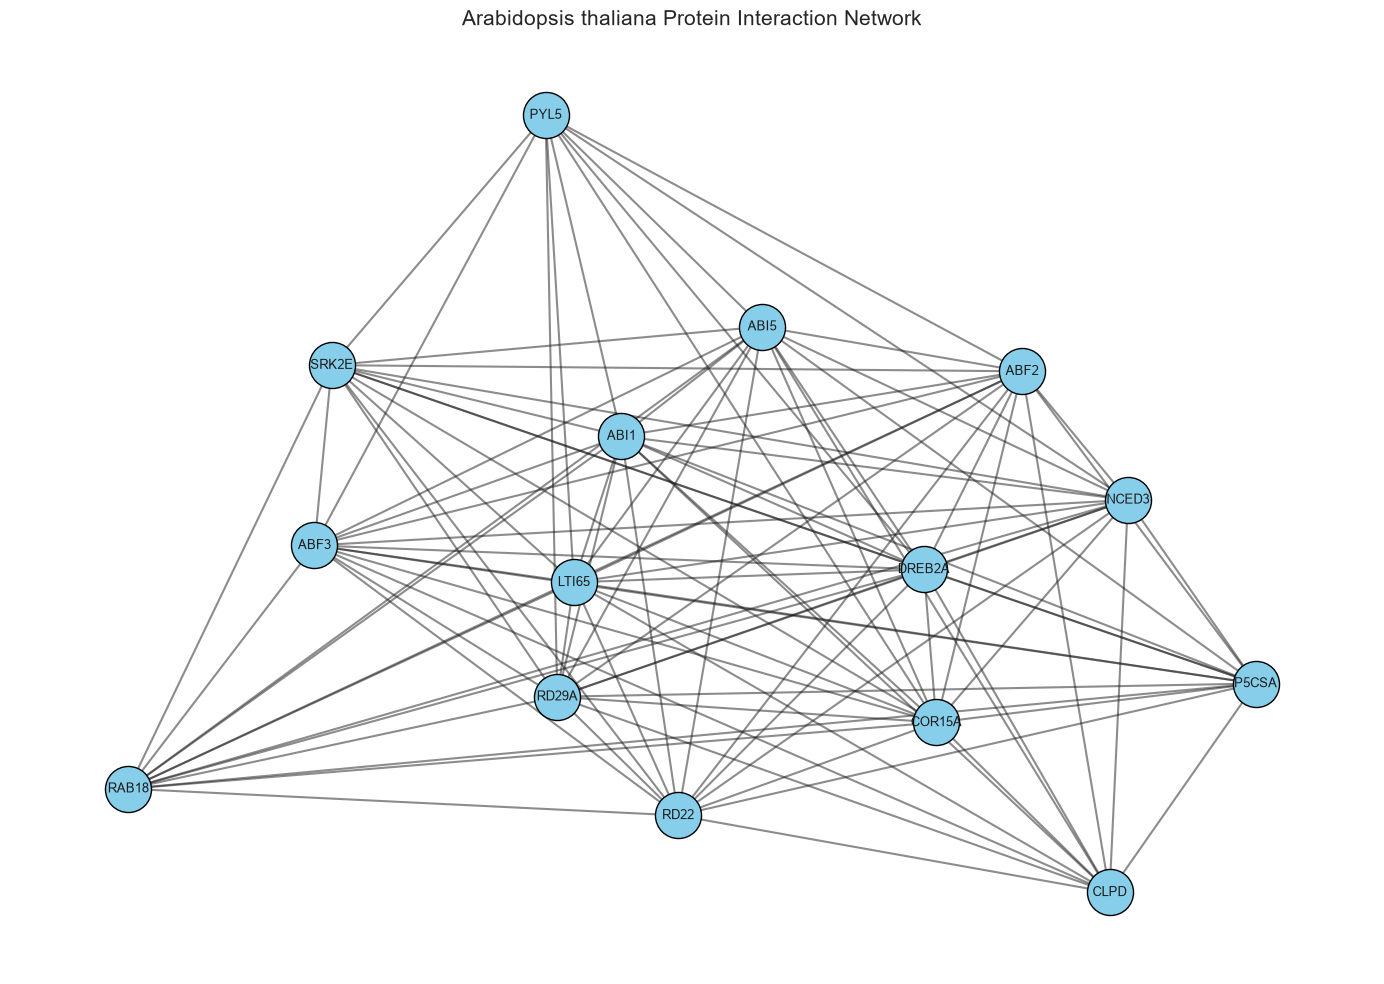


Protein interaction analysis completed!


In [23]:

import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
from IPython.display import display

# 1. Candidate genes
genes = candidate_genes["Gene_ID"].dropna().unique().tolist()

print("Number of input genes:", len(genes))

# 2. STRING API
url = "https://string-db.org/api/tsv/network"

params = {
    "identifiers": "\r".join(genes),
    "species": 3702,
    "required_score": 150,
    "caller_identity": "PlantBioinformatics_Student"
}

response = requests.post(
    url,
    data=params,
    timeout=120
)

print("STRING API status:", response.status_code)
response.raise_for_status()

# 3. Read interaction results
if not response.text.strip():
    raise ValueError(
        "STRING returned no interactions. "
        "Check internet connection and gene identifiers."
    )

ppi_data = pd.read_csv(
    StringIO(response.text),
    sep="\t"
)

print("Retrieved interactions:", len(ppi_data))

# 4. Build interaction network
G = nx.Graph()

for _, row in ppi_data.iterrows():

    protein_a = row["preferredName_A"]
    protein_b = row["preferredName_B"]
    score = row["score"]

    G.add_edge(
        protein_a,
        protein_b,
        weight=score
    )

# 5. Network statistics
print("\nNETWORK STATISTICS")
print("----------------------")
print("Number of proteins:", G.number_of_nodes())
print("Number of interactions:", G.number_of_edges())

# 6. Calculate centrality
degree = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(G)

hub_table = pd.DataFrame({
    "Protein": list(G.nodes()),
    "Degree_Centrality": [
        degree[n] for n in G.nodes()
    ],
    "Betweenness_Centrality": [
        betweenness[n] for n in G.nodes()
    ],
    "Interaction_Count": [
        G.degree(n) for n in G.nodes()
    ]
})

hub_table = hub_table.sort_values(
    "Interaction_Count",
    ascending=False
)

print("\nTOP HUB PROTEINS")
display(hub_table.head(10))

# 7. Visualize network
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.8
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=1100,
    node_color="skyblue",
    edgecolors="black"
)

nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.5,
    width=1.5
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9
)

plt.title(
    "Arabidopsis thaliana Protein Interaction Network",
    fontsize=15
)

plt.axis("off")
plt.tight_layout()
plt.show()

# 8. Save results
ppi_data.to_csv(
    "Arabidopsis_Protein_Interactions.csv",
    index=False
)

hub_table.to_csv(
    "Arabidopsis_Hub_Proteins.csv",
    index=False
)

print("\nProtein interaction analysis completed!")


,Protein,Interaction_Count
0,DREB2A,14
5,ABI5,14
7,ABI1,14
8,NCED3,14
9,COR15A,14
11,ABF3,14
12,ABF2,14
13,LTI65,14
14,RD29A,14
3,SRK2E,13


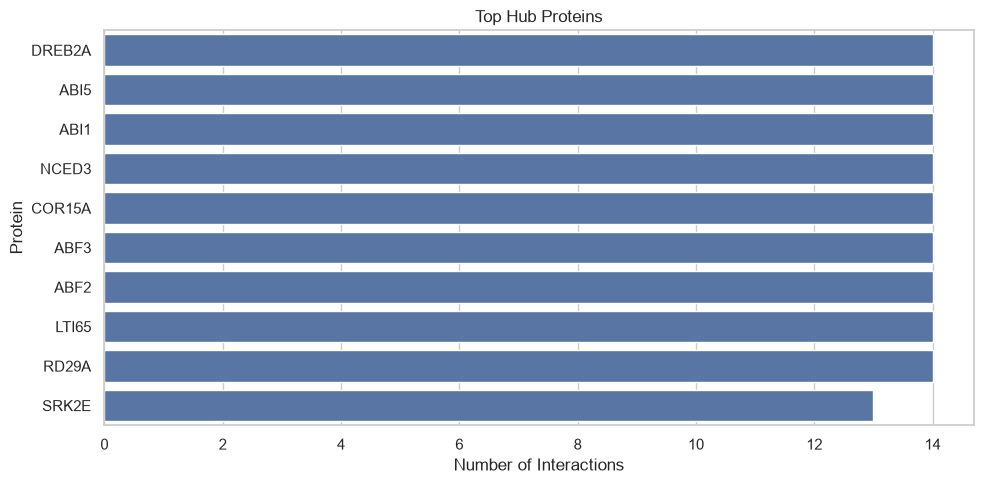

In [25]:

degree_values = dict(G.degree())

hub_genes = pd.DataFrame({
    "Protein": list(degree_values.keys()),
    "Interaction_Count": list(degree_values.values())
})

hub_genes = hub_genes.sort_values(
    "Interaction_Count",
    ascending=False
)

display(hub_genes.head(10))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=hub_genes.head(10),
    x="Interaction_Count",
    y="Protein"
)

plt.title("Top Hub Proteins")
plt.xlabel("Number of Interactions")
plt.ylabel("Protein")

plt.tight_layout()
plt.show()


In [26]:

if G.number_of_nodes() > 0:

    degree_centrality = nx.degree_centrality(G)

    betweenness_centrality = nx.betweenness_centrality(G)

    centrality_table = pd.DataFrame({
        "Protein": list(G.nodes()),
        "Degree_Centrality": [
            degree_centrality[node] for node in G.nodes()
        ],
        "Betweenness_Centrality": [
            betweenness_centrality[node] for node in G.nodes()
        ]
    })

    centrality_table = centrality_table.sort_values(
        "Degree_Centrality",
        ascending=False
    )

    display(centrality_table.head(10))

else:
    print("Network is empty. Centrality analysis skipped.")


,Protein,Degree_Centrality,Betweenness_Centrality
0,DREB2A,1.000000,0.006516
5,ABI5,1.000000,0.006516
7,ABI1,1.000000,0.006516
8,NCED3,1.000000,0.006516
9,COR15A,1.000000,0.006516
11,ABF3,1.000000,0.006516
12,ABF2,1.000000,0.006516
13,LTI65,1.000000,0.006516
14,RD29A,1.000000,0.006516
3,SRK2E,0.928571,0.003297


In [27]:

candidate_analysis = candidate_genes.copy()

if not hub_genes.empty:

    candidate_analysis = candidate_analysis.merge(
        hub_genes,
        left_on="Gene_Name",
        right_on="Protein",
        how="left"
    )

else:

    candidate_analysis["Interaction_Count"] = 0

candidate_analysis["Interaction_Count"] = (
    candidate_analysis["Interaction_Count"].fillna(0)
)

display(candidate_analysis)


,Gene_ID,Gene_Name,Functional_Category,Protein,Interaction_Count
0,AT5G05410,DREB2A,Transcription factor,DREB2A,14.0
1,AT5G52310,RD29A,Drought response,RD29A,14.0
2,AT5G52300,RD29B,Drought response,NaN,0.0
3,AT3G14440,NCED3,ABA biosynthesis,NCED3,14.0
4,AT1G45249,AREB1,ABA signaling,NaN,0.0
5,AT4G34000,ABF3,ABA signaling,ABF3,14.0
6,AT2G39800,P5CS1,Osmotic stress,NaN,0.0
7,AT5G66400,RAB18,Stress response,RAB18,12.0
8,AT2G42540,COR15A,Stress protection,COR15A,14.0
9,AT5G25610,RD22,Drought response,RD22,13.0


In [28]:

import os

expression_file = "Plant_Normalized_Expression.csv"

if os.path.exists(expression_file):

    expression_data = pd.read_csv(
        expression_file,
        index_col=0
    )

    print("Previous lecture data loaded successfully!")

else:

    print("Previous lecture file not found.")
    print("Creating a demonstration expression dataset.")

    np.random.seed(42)

    genes = [f"Gene_{i:04d}" for i in range(1, 1001)]

    samples = (
        [f"Control_{i}" for i in range(1, 7)] +
        [f"Drought_{i}" for i in range(1, 7)]
    )

    base = np.random.lognormal(
        mean=5,
        sigma=1,
        size=1000
    )

    changes = np.zeros(1000)
    changes[:50] = 2
    changes[50:100] = -2

    data = {}

    for sample in samples:

        if "Drought" in sample:
            means = base * (2 ** changes)
        else:
            means = base

        data[sample] = np.random.poisson(means)

    expression_data = pd.DataFrame(
        data,
        index=genes
    ).T

display(expression_data.head())
print("Expression matrix shape:", expression_data.shape)


Previous lecture file not found.
Creating a demonstration expression dataset.


,Gene_0001,Gene_0002,Gene_0003,Gene_0004,Gene_0005,Gene_0006,Gene_0007,Gene_0008,Gene_0009,Gene_0010,...,Gene_0991,Gene_0992,Gene_0993,Gene_0994,Gene_0995,Gene_0996,Gene_0997,Gene_0998,Gene_0999,Gene_1000
Control_1,227,134,246,697,124,112,674,322,91,256,...,166,15,106,84,56,108,884,284,92,271
Control_2,230,120,299,701,116,100,766,308,85,254,...,190,26,110,81,48,105,871,274,94,245
Control_3,249,133,277,707,141,127,760,339,83,274,...,175,18,118,70,64,96,883,275,86,248
Control_4,259,112,294,690,124,112,696,349,90,261,...,179,20,132,82,72,115,881,285,70,275
Control_5,268,122,280,686,126,101,677,341,110,261,...,188,15,143,72,61,101,910,305,82,271


Expression matrix shape: (12, 1000)


In [29]:

gene_expression = np.log2(
    expression_data.T + 1
)

print("Genes:", gene_expression.shape[0])
print("Samples:", gene_expression.shape[1])

display(gene_expression.head())


Genes: 1000
Samples: 12


,Control_1,Control_2,Control_3,Control_4,Control_5,Control_6,Drought_1,Drought_2,Drought_3,Drought_4,Drought_5,Drought_6
Gene_0001,7.832890,7.851749,7.965784,8.022368,8.071462,7.845490,9.974415,9.970106,9.899357,9.968667,9.929258,9.915879
Gene_0002,7.076816,6.918863,7.066089,6.820179,6.942515,7.139551,8.954196,9.044394,9.052568,9.118941,9.131857,9.033423
Gene_0003,7.948367,8.228819,8.118941,8.204571,8.134426,8.149747,10.166163,10.149747,10.192293,10.215533,10.172428,10.205793
Gene_0004,9.447083,9.455327,9.467606,9.432542,9.424166,9.317413,11.435670,11.402479,11.446566,11.370142,11.480790,11.412041
Gene_0005,6.965784,6.870365,7.149747,6.965784,6.988685,7.000000,8.939579,8.873444,8.962896,8.845490,8.885696,8.823367


In [30]:

gene_variance = gene_expression.var(axis=1)

top_variable_genes = gene_variance.sort_values(
    ascending=False
).head(500).index

variable_expression = gene_expression.loc[
    top_variable_genes
]

print("Selected variable genes:", len(top_variable_genes))


Selected variable genes: 500


In [31]:

scaler = StandardScaler()

scaled_expression = scaler.fit_transform(
    variable_expression
)

print("Standardization completed!")
print("Matrix dimensions:", scaled_expression.shape)


Standardization completed!
Matrix dimensions: (500, 12)


In [32]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(
    scaled_expression
)

cluster_results = pd.DataFrame({
    "Gene_ID": variable_expression.index,
    "Cluster": cluster_labels
})

print("Clustering completed!")

display(cluster_results.head(15))


Clustering completed!


,Gene_ID,Cluster
0,Gene_0064,1
1,Gene_0075,1
2,Gene_0014,1
3,Gene_0089,1
4,Gene_0080,1
5,Gene_0062,0
6,Gene_0025,2
7,Gene_0058,0
8,Gene_0077,0
9,Gene_0063,1


In [33]:

silhouette = silhouette_score(
    scaled_expression,
    cluster_labels
)

print("Silhouette Score:", round(silhouette, 4))


Silhouette Score: 0.3986


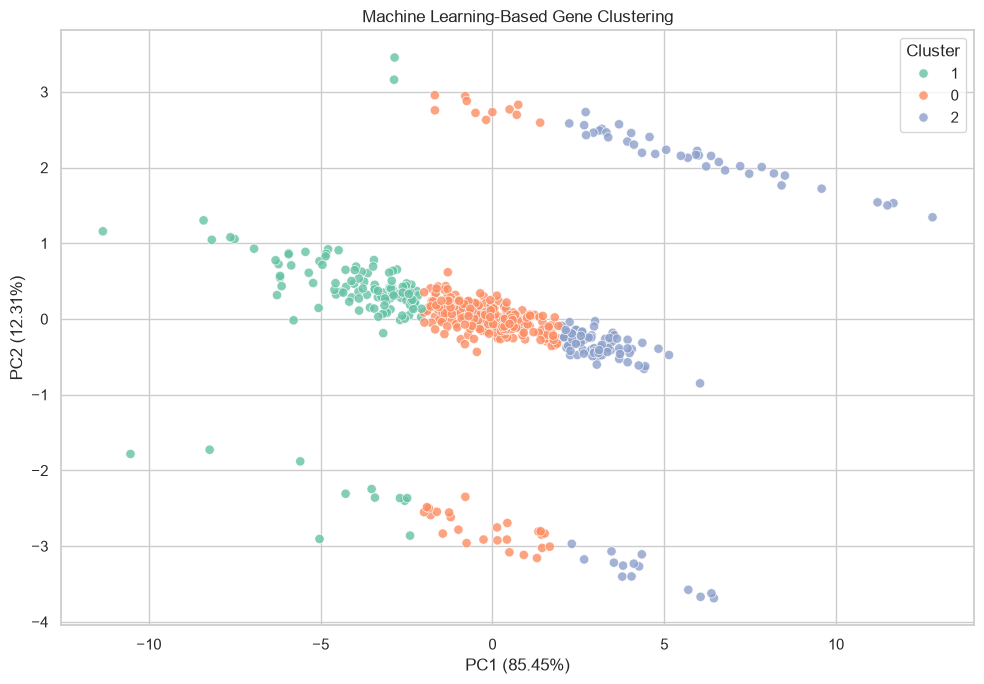

In [34]:

pca = PCA(n_components=2)

pca_coordinates = pca.fit_transform(
    scaled_expression
)

pca_df = pd.DataFrame({
    "PC1": pca_coordinates[:, 0],
    "PC2": pca_coordinates[:, 1],
    "Cluster": cluster_labels.astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=45,
    alpha=0.8
)

plt.title("Machine Learning-Based Gene Clustering")
plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)

plt.tight_layout()
plt.show()


In [35]:

cluster_expression = variable_expression.copy()

cluster_expression["Cluster"] = cluster_labels

control_samples = [
    col for col in cluster_expression.columns
    if "Control" in col
]

drought_samples = [
    col for col in cluster_expression.columns
    if "Drought" in col
]

cluster_summary = pd.DataFrame({
    "Control_Mean": cluster_expression[control_samples].mean(axis=1),
    "Drought_Mean": cluster_expression[drought_samples].mean(axis=1),
    "Cluster": cluster_labels
})

cluster_summary["Expression_Difference"] = (
    cluster_summary["Drought_Mean"] -
    cluster_summary["Control_Mean"]
)

display(
    cluster_summary.groupby("Cluster")[
        ["Control_Mean", "Drought_Mean", "Expression_Difference"]
    ].mean()
)


,Control_Mean,Drought_Mean,Expression_Difference
Cluster,,,
0,6.323571,6.208501,-0.115070
1,5.030004,4.861407,-0.168598
2,7.568874,7.941788,0.372914


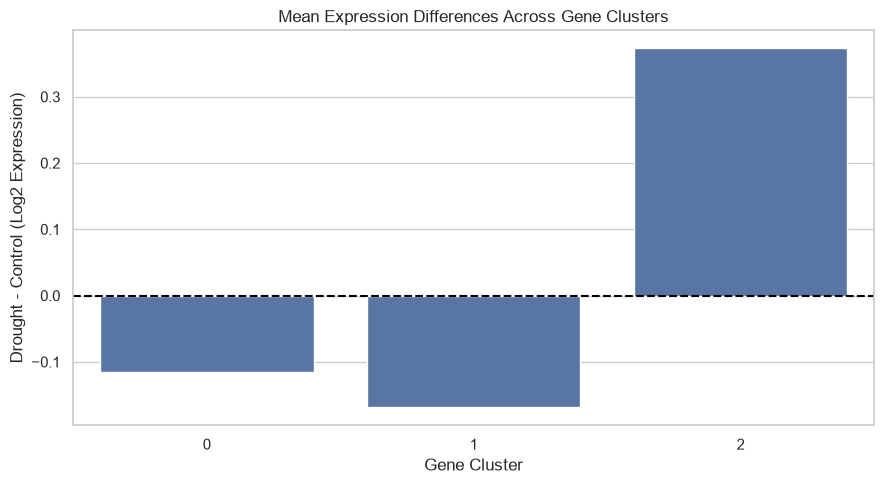

In [36]:

cluster_plot = (
    cluster_summary.groupby("Cluster")[
        "Expression_Difference"
    ].mean().reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_plot,
    x="Cluster",
    y="Expression_Difference"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Mean Expression Differences Across Gene Clusters")
plt.xlabel("Gene Cluster")
plt.ylabel("Drought - Control (Log2 Expression)")

plt.tight_layout()
plt.show()


In [37]:

keywords = [
    "drought",
    "water deprivation",
    "water",
    "osmotic",
    "abscisic acid",
    "salt stress",
    "oxidative stress",
    "response to stress"
]

if not annotation_results.empty:

    annotation_results["Relevant"] = (
        annotation_results["name"]
        .str.lower()
        .apply(
            lambda term: any(
                keyword in term for keyword in keywords
            )
        )
    )

    stress_annotations = annotation_results[
        annotation_results["Relevant"]
    ].copy()

    display(
        stress_annotations[
            ["source", "name", "p_value"]
        ].sort_values("p_value")
    )

    print("Stress-related terms:", len(stress_annotations))


,source,name,p_value
0,GO:BP,response to water deprivation,6.296603e-14
1,GO:BP,response to water,8.572724e-14
3,GO:BP,response to salt stress,1.191981e-11
4,GO:BP,response to osmotic stress,7.617218e-11
6,GO:BP,response to abscisic acid,2.456448e-10
11,GO:BP,abscisic acid-activated signaling pathway,1.590988e-07
12,GO:BP,cellular response to abscisic acid stimulus,3.214271e-07
14,GO:BP,response to stress,2.959742e-06
27,GO:BP,hyperosmotic salinity response,2.567412e-03
30,GO:BP,hyperosmotic response,4.457903e-03


Stress-related terms: 10


In [38]:

priority_table = candidate_analysis.copy()

priority_table["Network_Score"] = (
    priority_table["Interaction_Count"]
)

if "Degree_Centrality" in centrality_table.columns:

    priority_table = priority_table.merge(
        centrality_table[
            ["Protein", "Degree_Centrality"]
        ],
        left_on="Gene_Name",
        right_on="Protein",
        how="left"
    )

    priority_table["Degree_Centrality"] = (
        priority_table["Degree_Centrality"].fillna(0)
    )

priority_table = priority_table.sort_values(
    "Network_Score",
    ascending=False
)

display(priority_table)


,Gene_ID,Gene_Name,Functional_Category,Protein_x,Interaction_Count,Network_Score,Protein_y,Degree_Centrality
0,AT5G05410,DREB2A,Transcription factor,DREB2A,14.0,14.0,DREB2A,1.000000
1,AT5G52310,RD29A,Drought response,RD29A,14.0,14.0,RD29A,1.000000
3,AT3G14440,NCED3,ABA biosynthesis,NCED3,14.0,14.0,NCED3,1.000000
5,AT4G34000,ABF3,ABA signaling,ABF3,14.0,14.0,ABF3,1.000000
8,AT2G42540,COR15A,Stress protection,COR15A,14.0,14.0,COR15A,1.000000
12,AT4G26080,ABI1,ABA signaling,ABI1,14.0,14.0,ABI1,1.000000
13,AT2G36270,ABI5,Transcription factor,ABI5,14.0,14.0,ABI5,1.000000
9,AT5G25610,RD22,Drought response,RD22,13.0,13.0,RD22,0.928571
7,AT5G66400,RAB18,Stress response,RAB18,12.0,12.0,RAB18,0.857143
14,AT5G05440,PYL5,ABA receptor,PYL5,10.0,10.0,PYL5,0.714286


In [39]:

print("=" * 55)
print("PLANT FUNCTIONAL GENOMICS: RESEARCH SUMMARY")
print("=" * 55)

print("\n1. Candidate Gene Identification")
print("Total candidate genes:", len(candidate_genes))

print("\n2. Functional Annotation")
print("Total functional terms:", len(annotation_results))

print("\n3. GO Enrichment")
print("Significant terms:", len(significant_go))

print("\n4. Protein Interaction Network")
print("Proteins:", G.number_of_nodes())
print("Interactions:", G.number_of_edges())

print("\n5. Machine Learning")
print("Genes clustered:", len(cluster_results))
print("Number of clusters:", len(set(cluster_labels)))
print("Silhouette Score:", round(silhouette, 4))

print("\n6. Research Outputs")
print("Candidate gene prioritization completed.")

print("=" * 55)


PLANT FUNCTIONAL GENOMICS: RESEARCH SUMMARY

1. Candidate Gene Identification
Total candidate genes: 15

2. Functional Annotation
Total functional terms: 34

3. GO Enrichment
Significant terms: 34

4. Protein Interaction Network
Proteins: 15
Interactions: 99

5. Machine Learning
Genes clustered: 500
Number of clusters: 3
Silhouette Score: 0.3986

6. Research Outputs
Candidate gene prioritization completed.
